# Trading ERCOT congestion with PTP Obligations

*Applied Algorithmic Trading, group project.* We trade Point-to-Point (PTP) Obligations from **HB_WEST to
HB_NORTH** in the Texas power market (ERCOT).

## Overview: what we trade and why

**How the market works (simplified).** ERCOT runs the Texas power grid. Power has a price at each location; we
use the big regional averages, called **hubs** (West, North, South, Houston, Panhandle). Every hour has two
prices:

- **Day-ahead (DA) price.** The day before delivery, generators offer power ("I'll produce X MW at Y USD") and
  buyers bid for each hour of tomorrow. An auction matches them and sets one price per hour and hub. It is a
  *plan*, based on forecasts of demand, wind and sun.
- **Real-time (RT) price.** On the day itself, ERCOT balances supply and demand every 5 minutes, and the price
  reflects what actually happens: a wind drop, a plant failure, a hot afternoon. We use the hourly average.
- Anyone whose plan differs from reality settles the difference at the RT price. So RT is the "truth" and DA is
  the market's forecast of it. Usually the two are close, but sometimes RT moves a lot.

**Congestion.** West Texas has a lot of wind and solar but few people; Dallas (North) uses a lot of power. When
the power lines between them are full, power gets cheap in the West and expensive in the North. That price
difference between two hubs is **congestion**.

**Our instrument: a PTP Obligation.** A financial contract between two hubs, bought in the day-ahead auction. No
physical power changes hands; it is a pure bet on congestion. Per MW and hour, a West→North position:
- costs the day-ahead difference, `DA gap = DA[North] − DA[West]`;
- pays the real-time difference, `RT gap = RT[North] − RT[West]`.

> **profit = RT gap − DA gap** = how wrong the auction was about congestion

We call this the **auction's error**, and it is what we forecast. If we expect the auction to *underprice*
tomorrow's congestion (positive error), we buy West→North. If we expect it to *overprice* it, we buy the reverse.

**The idea.** Use public information available before the bid deadline (past prices and ERCOT's wind, solar and
load forecasts) to forecast tomorrow's 24 hourly errors, and trade only the hours where the model is confident.

**Rules of the game.**
- **No look-ahead.** Bids for day T are due at 10:00 on T−1. At that time real-time results are known only up
  to T−2. Every input and trading rule uses only that information, and automated tests in `tests/` check it.
- **Honest testing.** Our price history starts in December 2023, so we tune on 2024 and test on 2025–2026,
  which the models never saw.
- **Costs.** We pay an assumed 0.50 USD/MWh fee.
- **Luck check.** We test whether profits could be luck.

**Result in one sentence:** our model forecasts the auction's error better than the alternatives, but after fees
that isn't enough to make reliable money. The auction already prices the public information well.

**Contents:** 1. Data · 2. Models · 3. Do fundamentals help? · 4. Backtest · 5. Conclusions

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from backtest import LABELS, block_bootstrap
from compare_models import OUT, pinball
from config import OUTPUT, PERIODS, QCOLS, QUANTILES
from covariates import load_covariates
from processing import load_hourly
from spreads import build_spreads

COLORS = {"lgbm": "#2a78d6", "chronos": "#eb6834", "baseline": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e4e3df", "legend.frameon": False})
FIG = OUTPUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

wn = build_spreads(load_hourly(), [("HB_WEST", "HB_NORTH")])   # one row per hour: da_gap, rt_gap, error
print(f"{len(wn):,} hours, {wn.delivery_date.min():%Y-%m-%d} to {wn.delivery_date.max():%Y-%m-%d}")

25,295 hours, 2023-12-13 to 2026-10-31


## 1. The data

Hourly day-ahead and real-time prices for the five hubs, downloaded from ERCOT's public API
(December 2023 – October 2026). The chart compares, for West→North, what the auction priced (DA gap) with what
actually happened (RT gap).

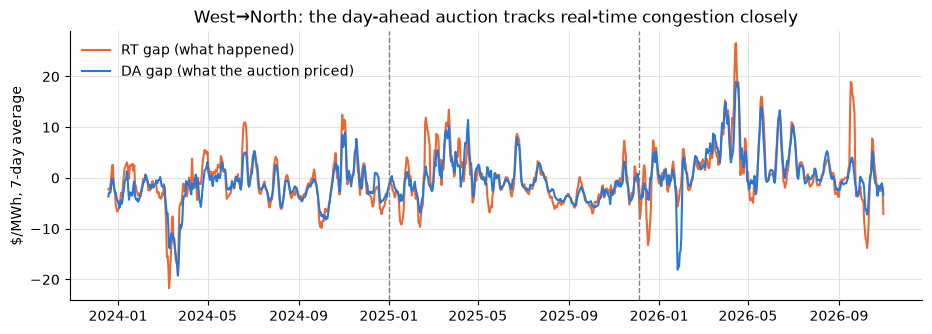

Auction error per hour: mean $0.19, std $11.73, 0.6% of hours beyond ±$50, largest $527


In [2]:
daily = wn.groupby("delivery_date")[["da_gap", "rt_gap", "error"]].mean().rolling(7).mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.rt_gap, color=COLORS["chronos"], label="RT gap (what happened)")
ax.plot(daily.index, daily.da_gap, color=COLORS["lgbm"], label="DA gap (what the auction priced)")
for p in ("test_a", "test_b"):
    ax.axvline(pd.Timestamp(PERIODS[p][0]), color="gray", ls="--", lw=1)
ax.set_ylabel("$/MWh, 7-day average"); ax.legend(loc="upper left")
ax.set_title("West→North: the day-ahead auction tracks real-time congestion closely")
fig.savefig(FIG / "gaps_over_time.png", bbox_inches="tight", dpi=150); plt.show()

e = wn.error
print(f"Auction error per hour: mean ${e.mean():.2f}, std ${e.std():.2f}, "
      f"{(e.abs() > 50).mean():.1%} of hours beyond ±$50, largest ${e.max():.0f}")

**Takeaways.**
- The auction already prices most congestion: the two lines move together.
- The error averages about zero, so simply always betting one direction doesn't work.
- The error has fat tails: most hours are close to 0 USD, but a few hours have errors of hundreds of dollars and
  dominate any total. That's why we always show confidence intervals, not only a single PnL number.

**Why West→North?** With five hubs there are 10 possible pairs. We tested all of them on 2024 data only, so the
test years played no part in the choice. For each pair we checked whether the error has a constant bias (none
had a useful one) and whether our models' most confident trades made money after fees. West→North was
profitable under every model we tried. It also has the clearest physical story: West Texas wind runs into the
limits of the power lines to Dallas, and ERCOT publishes wind and load forecasts for exactly those regions.
Pairs with the Panhandle hub swing hard but no model predicted them consistently.

### Test periods and the December 2025 market change

| Period | Dates | Use |
|---|---|---|
| 2024 | Jan–Dec 2024 | tuning (in-sample) |
| Test A | 1 Jan – 4 Dec 2025 | out of sample |
| Test B | 5 Dec 2025 – 31 Oct 2026 | out of sample, after the market change |

On **5 Dec 2025** ERCOT launched **RTC+B (Real-Time Co-optimization plus Batteries)**, which ERCOT calls its
biggest real-time market change since 2010:
- Real time now buys power *and* reserves together, every 5 minutes, instead of separately.
- Batteries are modelled properly, including how much charge they have left.
- ERCOT expects better congestion management.

This changes how real-time prices behave, and real-time is the half of our profit we can't see in advance. A
model tuned on the old market may not fit the new one, so we report Test A (before) and Test B (after)
separately. The data shows the change:

In [3]:
wn["period"] = pd.cut(wn.delivery_date, [pd.Timestamp("2023-12-31")] + [pd.Timestamp(PERIODS[p][1]) for p in PERIODS],
                      labels=["2024", "Test A", "Test B (after RTC+B)"])
wn.groupby("period", observed=True).agg(
    avg_DA_gap=("da_gap", "mean"), avg_error=("error", "mean"), error_std=("error", "std"),
    share_hours_error_over_50=("error", lambda e: (e.abs() > 50).mean())).round(3)

,avg_DA_gap,avg_error,error_std,share_hours_error_over_50
period,,,,
2024,-1.875,0.344,10.389,0.006
Test A,-0.834,0.017,9.739,0.004
Test B (after RTC+B),1.844,0.191,14.738,0.009


After the change, the error is about 50% more volatile (std ≈ 15 USD vs ≈ 10 USD), extreme hours (|error| > 50 USD) are
more common (0.9% vs 0.4–0.6%), and the average DA gap flipped sign. Models built on the old market face a
different game.

## 2. Forecasting models

Each model forecasts tomorrow's 24 hourly errors as a **range** rather than one number: 9 quantiles from 10% to
90%. The 50% quantile (median) is the best guess; a narrow range means the model is confident, a wide one means
it isn't. The trading rules use both.

We compare three models, from simplest to most complex:

| Model | Type | How it works |
|---|---|---|
| **Hour-of-day baseline** | simple statistics | • per hour: spread of that hour's errors over the last 90 days<br>• no learning, no weather data<br>• the bar to beat |
| **LightGBM** | decision trees (gradient boosting) | • 300 small trees, each fixes the previous trees' mistakes<br>• inputs: past errors, calendar, wind/solar/load forecasts<br>• max 15 leaves (5–11 levels), ≥ 50 hours per leaf, learning rate 0.03<br>• retrained monthly on data known at the time<br>• some overfitting: 8% better than zero forecast in-sample, 1% out of sample |
| **Chronos-2** (Amazon) | foundation model (neural network) | • transformer pretrained on huge numbers of time series<br>• zero-shot: sees only our error history, no training on our data |

Why both? Chronos-2 tests whether a big general-purpose model works out of the box. LightGBM tests whether
domain knowledge (wind, load) beats that. We also tried two other foundation models, TimesFM (Google) and
TabPFN-TS. On 2024 they scored about the same as Chronos-2, so we kept only Chronos-2 for comparison.

**Example: what the models predict.** Forecasts for 14 May 2025 (Test A), made at 10:00 on 13 May. Each model gives
nine quantiles per hour: the 10% column means "only a 10% chance the error ends up below this", the 50% column is
the median (best guess), and so on. *Decision* applies our rule (median more than 2 USD from zero); *actual* is the
error that really happened; *PnL* is per MW after the 0.50 USD fee.

In [4]:
MODELS = {"lgbm": "lgbm_cov_monthly{s}", "chronos": "chronos_ctx2048_WEST-NORTH{s}",
          "baseline": "baseline_ctx2160{w}{s}"}

def load(model, period):
    s = "" if period == "train" else f"_{period}"
    f = pd.read_csv(OUT / (MODELS[model].format(s=s, w="_WEST-NORTH" if s else "") + ".csv"))
    f = f[f.pair == "HB_WEST->HB_NORTH"]
    f["hour_ending"] = pd.to_datetime(f.hour_ending, utc=True)
    return f.drop(columns="delivery_date").merge(wn, on="hour_ending")

rows = []
for m, hour in [("lgbm", 17), ("chronos", 17), ("baseline", 17), ("lgbm", 20)]:
    f = load(m, "test_a")
    r = f[(f.delivery_date == "2025-05-14") & (f.hour == hour)].iloc[0]
    side = 1 if r.q50 > 2 else -1 if r.q50 < -2 else 0
    rows.append({"hour": f"{hour}:00–{hour + 1}:00", "model": LABELS[m],
                 **{f"{c[1:]}%": r[c] for c in QCOLS},
                 "decision": {1: "buy West→North", -1: "buy North→West", 0: "no trade"}[side],
                 "actual": r.error, "PnL $/MWh": side * r.error - 0.5 * abs(side) + 0.0})   # + 0.0 avoids "-0.0"
pd.DataFrame(rows).set_index(["hour", "model"]).round(1)

10%   20%   30%   40%  50%  60%  70%  \
hour        model                                                            
17:00–18:00 LightGBM + fundamentals -23.6 -16.0 -14.3 -10.6 -7.6 -2.1  0.3   
            Chronos-2 (zero-shot)    -6.4  -3.3  -1.7  -0.7  0.1  0.9  1.8   
            Hour-of-day baseline    -11.1  -6.8  -1.8  -0.5  0.2  1.3  2.2   
20:00–21:00 LightGBM + fundamentals -24.0 -10.3  -6.7  -3.7 -1.8  1.2  2.5   

                                     80%   90%        decision  actual  \
hour        model                                                        
17:00–18:00 LightGBM + fundamentals  7.9  14.6  buy North→West   -68.4   
            Chronos-2 (zero-shot)    3.2   5.6        no trade   -68.4   
            Hour-of-day baseline     4.3   8.3        no trade   -68.4   
20:00–21:00 LightGBM + fundamentals  6.3  15.2        no trade   -33.5   

                                     PnL $/MWh  
hour        model                               
17:00–18:00 LightGBM + fundamentals       67.9  
            Chronos-2 (zero-shot)          0.0  
            Hour-of-day baseline           0.0  
20:00–21:00 LightGBM + fundamentals        0.0

- **LightGBM, 17:00:** most of its range is below zero (median −7.6 USD), so it expects the auction to *overprice*
  congestion and buys the reverse direction. The error came in at −68 USD: about +68 USD per MW.
- **Chronos-2 and the baseline:** medians near 0 USD (no view), so no trade.
- **LightGBM, 20:00:** median −1.8 USD is within ±2 USD, so no trade, even though the error was −34 USD.
- The ranges are wide even when the model is right. We picked this day because the models disagree on a big
  event; it's one of LightGBM's best days, not a typical one (on 17 Sep 2026 one hour lost 3,748 USD).

**How we score them.**
- **Pinball loss** measures the accuracy of the whole forecast range; lower is better. Each quantile is
  penalised asymmetrically. For example, the 90% quantile is punished hard for being too low and lightly for
  being too high, which pushes it to where 90% of outcomes fall below it. For the median it equals half the
  absolute error.
- **Top-500 PnL.** Trade 1 MW on each model's 500 most confident hours (largest |median|), in the direction of
  the median, after the 0.50 USD/MWh fee. This compares models at the same number of trades.
- **95% interval.** Checks whether a profit could be luck. A few extreme hours decide the totals, so one number
  isn't enough. We take the real daily profits, cut them into weeks, and build 5,000 "alternative years" by drawing
  real weeks at random (some twice, some not at all). The middle 95% of those totals is the interval. If it
  contains 0, we can't tell the profit from luck.
  - *Doesn't this break seasons and weather?* No. Each week keeps its real weather and the real trades the model
    made for it; only which weeks get counted changes. The order of weeks doesn't matter for a total.

In [5]:
rows = []
for p in PERIODS:
    for m in MODELS:
        f = load(m, p)
        y = f.error.to_numpy()
        top = f.loc[f.q50.abs().nlargest(500).index]
        pnl = np.sign(top.q50) * top.error - 0.5
        days = pnl.groupby(top.delivery_date).sum().reindex(f.delivery_date.unique(), fill_value=0).to_numpy()
        lo, hi = np.percentile(block_bootstrap(days).sum(1), [2.5, 97.5])
        rows.append({"period": p, "model": LABELS[m],
                     "pinball": np.mean([pinball(y, f[c], q).mean() for c, q in zip(QCOLS, QUANTILES)]),
                     "top-500 PnL $": pnl.sum(), "CI low": lo, "CI high": hi})
        if m == "lgbm" and p == "test_a":
            example_totals = block_bootstrap(days).sum(1)   # kept for the histogram below
scores = pd.DataFrame(rows).set_index(["period", "model"])
scores.round(1)

pinball  top-500 PnL $  CI low  CI high
period model                                                           
train  LightGBM + fundamentals      2.2         1763.9   177.6   3588.7
       Chronos-2 (zero-shot)        2.3         1051.2  -310.9   2661.3
       Hour-of-day baseline         2.2          653.6   -67.1   1363.0
test_a LightGBM + fundamentals      2.1          327.4  -877.7   1710.1
       Chronos-2 (zero-shot)        2.2         -243.3  -860.6    381.8
       Hour-of-day baseline         2.2           25.7  -662.4   1177.2
test_b LightGBM + fundamentals      2.4          594.1 -2164.4   4377.8
       Chronos-2 (zero-shot)        2.5        -2109.1 -4127.9   -484.0
       Hour-of-day baseline         2.4          230.5 -1696.9   2317.1

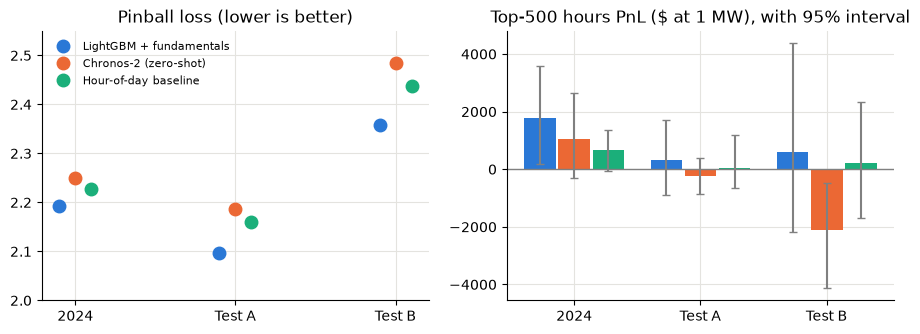

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(3)
for i, m in enumerate(MODELS):
    s = scores.xs(LABELS[m], level="model")
    axes[0].plot(x + (i - 1) * 0.1, s.pinball, "o", ms=9, color=COLORS[m], label=LABELS[m])   # dots: axis doesn't start at 0
    pnl = s["top-500 PnL $"]
    axes[1].bar(x + (i - 1) * 0.27, pnl, 0.25, color=COLORS[m],
                yerr=[pnl - s["CI low"], s["CI high"] - pnl], capsize=3, ecolor="gray")
axes[0].set_ylim(2.0, 2.55); axes[0].set_title("Pinball loss (lower is better)")
axes[1].axhline(0, color="gray", lw=1); axes[1].set_title("Top-500 hours PnL ($ at 1 MW), with 95% interval")
for ax in axes:
    ax.set_xticks(x, ["2024", "Test A", "Test B"])
axes[0].legend(fontsize=8)
fig.savefig(FIG / "model_comparison.png", bbox_inches="tight", dpi=150); plt.show()

**What the interval looks like.** The 5,000 "alternative year" totals for LightGBM's top-500 trades in Test A. The
shaded band is the 95% interval. Because it includes 0, the +327 USD profit could be luck.

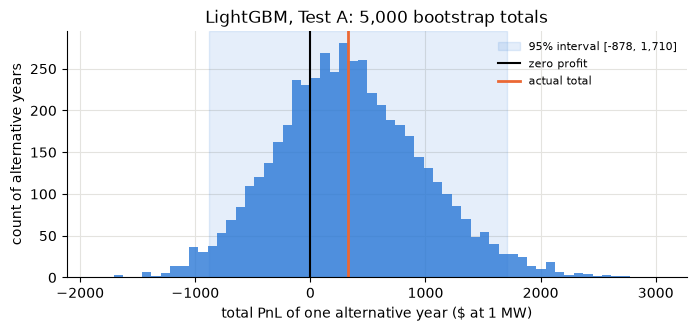

In [7]:
lo, hi = np.percentile(example_totals, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(example_totals, bins=60, color=COLORS["lgbm"], alpha=0.8)
ax.axvspan(lo, hi, color=COLORS["lgbm"], alpha=0.12, label=f"95% interval [{lo:,.0f}, {hi:,.0f}]")
ax.axvline(0, color="black", lw=1.5, label="zero profit")
ax.axvline(scores.loc[("test_a", LABELS["lgbm"]), "top-500 PnL $"], color=COLORS["chronos"], lw=2, label="actual total")
ax.set_xlabel("total PnL of one alternative year ($ at 1 MW)"); ax.set_ylabel("count of alternative years")
ax.set_title("LightGBM, Test A: 5,000 bootstrap totals"); ax.legend(fontsize=8)
fig.savefig(FIG / "bootstrap_interval.png", bbox_inches="tight", dpi=150); plt.show()

**Results.**
- **LightGBM has the best forecasts in all three periods.** Its pinball loss is 1.5–3% below the baseline.
- Chronos-2, despite being the biggest model, is slightly *worse* than the simple baseline on this pair. A
  general model trained on other data doesn't know the drivers of Texas congestion.
- Better forecasts don't automatically mean reliable profit. Out of sample, every interval contains 0, except
  Chronos-2 in Test B, which is a significant *loss*.

## 3. Does adding fundamental data on top of price history improve the forecast?

We train the **same LightGBM model twice**, with identical settings:
- **price history only:** past errors and gaps, plus the calendar (hour, weekday, month, holiday);
- **+ fundamentals:** the same, plus ERCOT's day-ahead forecasts of wind (West, Panhandle, system), solar, and load
  (North Central, Far West, Coast, system), and two derived values: net load (load − wind − solar) and West surplus
  (West generation − West load).

Any difference comes from the fundamentals alone.

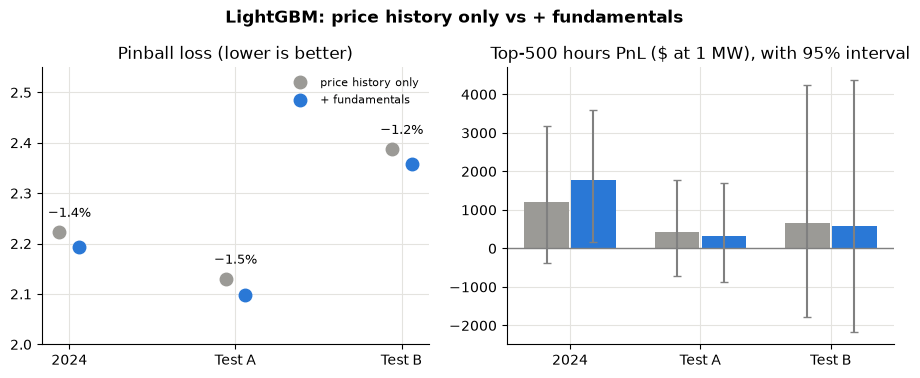

In [8]:
def score_file(stem):
    f = pd.read_csv(OUT / f"{stem}.csv")
    f = f[f.pair == "HB_WEST->HB_NORTH"]
    f["hour_ending"] = pd.to_datetime(f.hour_ending, utc=True)
    f = f.drop(columns="delivery_date").merge(wn, on="hour_ending")
    y = f.error.to_numpy()
    top = f.loc[f.q50.abs().nlargest(500).index]
    pnl = np.sign(top.q50) * top.error - 0.5
    days = pnl.groupby(top.delivery_date).sum().reindex(f.delivery_date.unique(), fill_value=0).to_numpy()
    lo, hi = np.percentile(block_bootstrap(days).sum(1), [2.5, 97.5])
    return {"pinball": np.mean([pinball(y, f[c], q).mean() for c, q in zip(QCOLS, QUANTILES)]),
            "top-500 PnL $": pnl.sum(), "CI low": lo, "CI high": hi}

res = {name: [score_file(f"{stem}{'' if p == 'train' else '_' + p}") for p in PERIODS]
       for name, stem in [("price history only", "lgbm_lags_monthly"), ("+ fundamentals", "lgbm_cov_monthly")]}
x, colors = np.arange(3), {"price history only": "#9b9a96", "+ fundamentals": COLORS["lgbm"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (name, rs) in enumerate(res.items()):
    pin = [r["pinball"] for r in rs]
    pnl = np.array([r["top-500 PnL $"] for r in rs])
    axes[0].plot(x + (i - 0.5) * 0.12, pin, "o", ms=9, color=colors[name], label=name)
    axes[1].bar(x + (i - 0.5) * 0.36, pnl, 0.34, color=colors[name], capsize=3, ecolor="gray",
                yerr=[pnl - [r["CI low"] for r in rs], [r["CI high"] for r in rs] - pnl])
for j in range(3):   # label the pinball improvement above each pair of dots
    base, fund = res["price history only"][j]["pinball"], res["+ fundamentals"][j]["pinball"]
    axes[0].annotate(f"−{(1 - fund / base) * 100:.1f}%", (x[j], base + 0.03), ha="center", fontsize=9)
axes[0].set_ylim(2.0, 2.55); axes[0].set_title("Pinball loss (lower is better)"); axes[0].legend(fontsize=8)
axes[1].axhline(0, color="gray", lw=1); axes[1].set_title("Top-500 hours PnL ($ at 1 MW), with 95% interval")
for ax in axes:
    ax.set_xticks(x, ["2024", "Test A", "Test B"])
fig.suptitle("LightGBM: price history only vs + fundamentals", fontweight="bold", y=1.04)
fig.savefig(FIG / "fundamentals_effect.png", bbox_inches="tight", dpi=150); plt.show()

**Result.**
- **Forecast accuracy: a small but consistent gain.** Fundamentals lower the pinball loss by about 1.2–1.5% in
  every period, including both test periods. That's small, but it never reverses.
- **Profit: no consistent gain.** Top-500 PnL is higher with fundamentals in 2024 but slightly lower in Test A and
  Test B, and the intervals overlap heavily. A better forecast on average doesn't mean better calls on the few
  hours that decide the total.

**Why so small?** Our thesis was that high West wind causes congestion the auction underprices. To test it, we
group all hours into 10 equal-sized buckets by ERCOT's West wind forecast. For each bucket we compare the actual
congestion (RT gap), the auction price (DA gap), and our profit (the error).

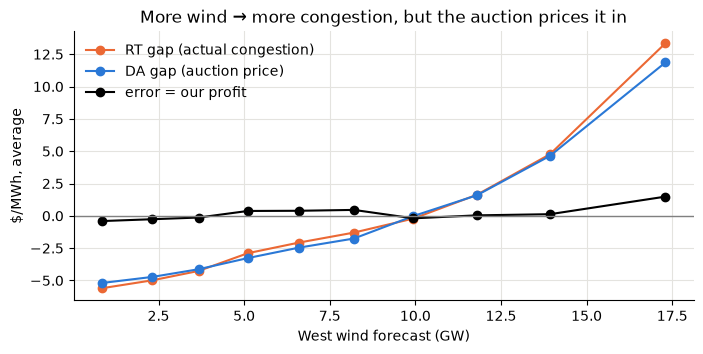

In [9]:
cov = load_covariates()
w = wn.join(cov["wind_west"], on="hour_ending").dropna()
g = w.groupby(pd.qcut(w.wind_west / 1000, 10), observed=True)[["rt_gap", "da_gap", "error"]].mean()
mid = [b.mid for b in g.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mid, g.rt_gap, "o-", color=COLORS["chronos"], label="RT gap (actual congestion)")
ax.plot(mid, g.da_gap, "o-", color=COLORS["lgbm"], label="DA gap (auction price)")
ax.plot(mid, g.error, "o-", color="black", label="error = our profit")
ax.axhline(0, color="gray", lw=1); ax.set_xlabel("West wind forecast (GW)"); ax.set_ylabel("$/MWh, average")
ax.set_title("More wind → more congestion, but the auction prices it in"); ax.legend()
fig.savefig(FIG / "wind_priced_in.png", bbox_inches="tight", dpi=150); plt.show()

**This is the key finding.** Congestion rises with West wind, and so does the auction price, almost one for one.
Our profit stays close to zero except in the windiest 10% of hours, where it's about +1.50 USD/MWh. That makes
sense: everyone bids with the same public forecasts, so the auction already includes them.

**More data.** We tested three more ERCOT datasets that are public before the bid, adding each one on its own:
- **Forecast misses:** actual minus forecast wind, solar and load, from the last settled day.
- **Shadow prices:** how expensive the West Texas export limits were in yesterday's auction.
- **Generator outages:** forecast MW out of service, by zone.

None of them improved results consistently: each helped in one period and hurt in another, by about 1% or less.
The final model is **LightGBM with wind, solar and load forecasts**.

## 4. Backtest

`src/backtest.py` turns forecasts into trades with the same rules for every model, using 1M USD of capital and
starting fresh in each period:

- **Entry.** Trade when the forecast median is more than **2 USD** from zero, in its direction. We tuned this on 2024
  over 2, 3 or 5 USD thresholds and three confidence levels. Only this setting gave more than 1,000 trades; the others
  were too few to trust.
- **Bid cap.** We never pay more than 25 USD/MWh for the position.
- **Size.** Half-Kelly (bigger when the model is more confident and its range is narrower), capped at **10 MW per
  hour** and **40 MW per day**. The most confident hours go first.
- **Costs.** 0.50 USD/MWh fee.

### Risk management

A PTP Obligation can't be closed early: once the auction clears, it is held until real-time settlement. So a
classic **stop-loss or take-profit on a single position isn't possible**. Instead, risk is controlled before the bid
(position limits) and between days (stops based on settled results, known at bid time on T−2):

| Technique | Rule | Purpose |
|---|---|---|
| Position limit per hour | max 10 MW per hour | caps the damage of one extreme hour |
| Position limit per day | max 40 MW per day, most confident hours first | caps daily exposure |
| Half-Kelly sizing | size grows with confidence, then capped | bet more only when the model is surer |
| Bid cap (price limit) | never pay more than 25 USD/MWh | don't buy when the auction already prices extreme congestion |
| Daily stop-loss | T−2 lost > 2% of equity → half size; > 5% → no trading | slow down after a bad day |
| Drawdown stop | equity 15% below its peak → stop for good | strategy-level stop-loss |
| Extreme-weather filter | any hub real-time price > 1,000 USD on T−2 → half size | trade smaller in stressed markets |

How often each one actually acted in the backtest:

In [10]:
rows = []
for m in MODELS:
    for p in PERIODS:
        d = pd.read_csv(OUTPUT / "backtest" / f"daily_{m}_{p}.csv")
        t = pd.read_csv(OUTPUT / "backtest" / f"trades_{m}_{p}.csv")
        rows.append({"model": LABELS[m], "period": p,
                     "trades at 10 MW cap %": (t.mw == 10).mean() * 100,
                     "bids rejected by $25 cap": int((~t.cleared).sum()),
                     "days size halved": int((d.scale == 0.5).sum()),
                     "days with no trading": int((d.scale == 0).sum()),
                     "worst day % of capital": d.pnl.min() / 1e6 * 100,
                     "max drawdown %": d.drawdown.min() * 100})
pd.DataFrame(rows).set_index(["period", "model"]).sort_index().round(2)

trades at 10 MW cap %  \
period model                                            
test_a Chronos-2 (zero-shot)                    100.0   
       Hour-of-day baseline                     100.0   
       LightGBM + fundamentals                  100.0   
test_b Chronos-2 (zero-shot)                    100.0   
       Hour-of-day baseline                     100.0   
       LightGBM + fundamentals                  100.0   
train  Chronos-2 (zero-shot)                    100.0   
       Hour-of-day baseline                     100.0   
       LightGBM + fundamentals                  100.0   

                                bids rejected by $25 cap  days size halved  \
period model                                                                 
test_a Chronos-2 (zero-shot)                           3                 3   
       Hour-of-day baseline                            7                 3   
       LightGBM + fundamentals                         1                 3   
test_b Chronos-2 (zero-shot)                           7                 2   
       Hour-of-day baseline                            0                 2   
       LightGBM + fundamentals                         0                 2   
train  Chronos-2 (zero-shot)                          13                 5   
       Hour-of-day baseline                            0                 5   
       LightGBM + fundamentals                         1                 5   

                                days with no trading  worst day % of capital  \
period model                                                                   
test_a Chronos-2 (zero-shot)                       0                   -0.08   
       Hour-of-day baseline                        0                   -0.10   
       LightGBM + fundamentals                     0                   -0.16   
test_b Chronos-2 (zero-shot)                       0                   -0.29   
       Hour-of-day baseline                        0                   -0.16   
       LightGBM + fundamentals                     0                   -0.69   
train  Chronos-2 (zero-shot)                       0                   -0.11   
       Hour-of-day baseline                        0                   -0.15   
       LightGBM + fundamentals                     0                   -0.30   

                                max drawdown %  
period model                                    
test_a Chronos-2 (zero-shot)             -0.20  
       Hour-of-day baseline              -0.34  
       LightGBM + fundamentals           -0.21  
test_b Chronos-2 (zero-shot)             -0.70  
       Hour-of-day baseline              -0.30  
       LightGBM + fundamentals           -0.91  
train  Chronos-2 (zero-shot)             -0.34  
       Hour-of-day baseline              -0.50  
       LightGBM + fundamentals           -0.78

**Reading this.**
- **The position limits do the real work.** Every trade hits the 10 MW cap (half-Kelly always asks for more), and
  the 40 MW/day budget keeps the worst day under 0.7% of capital.
- **The stop-losses never triggered.** The worst day lost at most 0.7% (the stop starts at 2%) and the deepest
  drawdown was under 1% (the stop is at 15%). At this size they're a safety net, not an active control.
- **Only the weather filter acted**, halving size on 2–5 days per period after price spikes.
- **The bid cap rarely binds:** at most 13 bids per period were rejected.

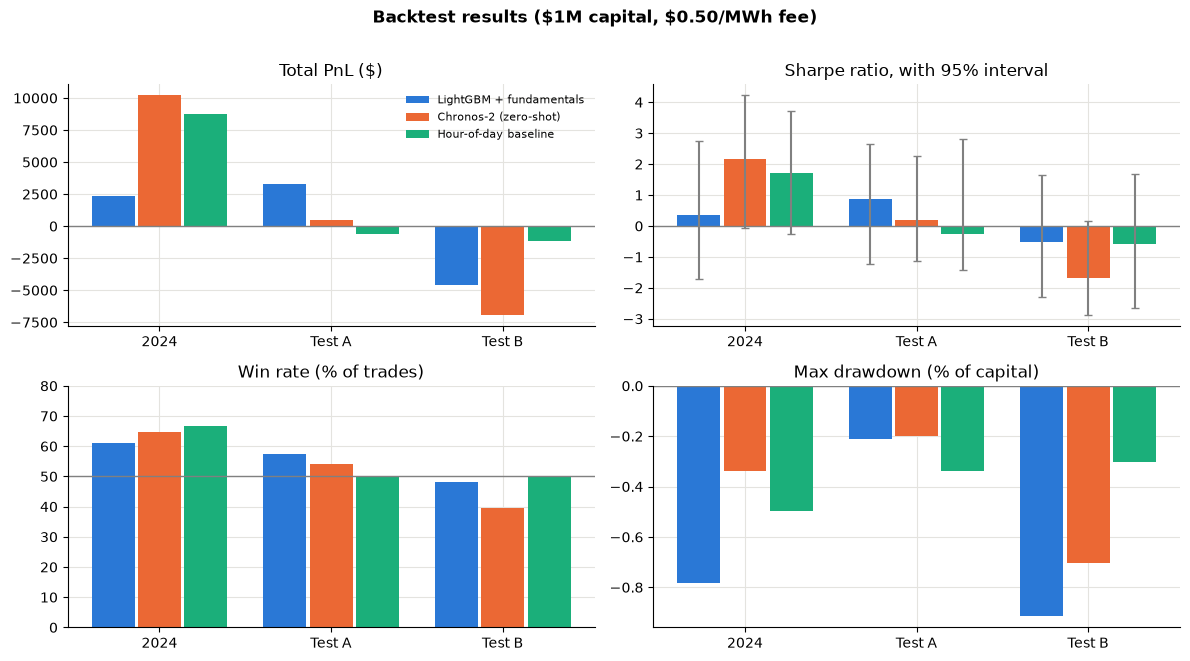

In [11]:
M = json.loads((OUTPUT / "metrics.json").read_text())["models"]
panels = [("total_pnl", "Total PnL ($)"), ("sharpe", "Sharpe ratio, with 95% interval"),
          ("win_rate", "Win rate (% of trades)"), ("max_drawdown_pct", "Max drawdown (% of capital)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
x = np.arange(3)
for ax, (key, title) in zip(axes.flat, panels):
    for i, m in enumerate(M):
        r = [M[m]["periods"][p] for p in PERIODS]
        v = np.array([q[key] * (100 if key == "win_rate" else 1) for q in r])
        err = None
        if key == "sharpe":
            err = [v - [q["sharpe_ci"][0] for q in r], [q["sharpe_ci"][1] for q in r] - v]
        ax.bar(x + (i - 1) * 0.27, v, 0.25, color=COLORS[m], label=LABELS[m], yerr=err, capsize=3, ecolor="gray")
    ax.axhline(50 if key == "win_rate" else 0, color="gray", lw=1)
    ax.set_xticks(x, ["2024", "Test A", "Test B"]); ax.set_title(title)
axes[1, 0].set_ylim(0, 80)
axes[0, 0].legend(fontsize=8)
fig.suptitle(r"Backtest results (\$1M capital, \$0.50/MWh fee)", fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "backtest_results.png", bbox_inches="tight", dpi=150); plt.show()

**Takeaways from the results chart.**
- **Total PnL:** the 2024 leaders (Chronos-2, baseline) fade out of sample. LightGBM is the only model ahead in
  Test A, and all three lose in Test B, after the market change.
- **Sharpe:** every 95% interval crosses zero, so none of these results can be told apart from luck.
- **Win rate:** about 60–67% in 2024, drifting to a coin flip (40–50%) in Test B. The in-sample edge doesn't carry over.
- **Max drawdown:** under 1% of capital everywhere. The risk is small because the positions are small, not
  because the strategy is safe.

**Why did Chronos-2 and the baseline look so good in 2024, and fade afterwards?**
- **2024 had a one-way bias.** The auction slightly underpriced West→North congestion almost all year: the median
  error was positive in all 12 months, and about 63% of hours had a positive error. Simply buying West→North won.
- **These two models rode that bias.** They extrapolate recent history, so they kept forecasting a positive error:
  the baseline bought West→North on 100% of its trades, Chronos-2 on 97%. Their profit came mainly from the months
  where the bias was strongest (January, March, April, June).
- **In 2025 the bias faded** to about a coin flip (around 54% positive hours), but both models kept betting the same
  direction, so they earned roughly nothing after fees. Why the bias faded we can't prove; more traders competing
  for it and grid changes in the West are plausible reasons.
- **LightGBM adapted better.** It was weaker in early 2024 (little training data, since our history starts in
  December 2023), but it learned to bet both ways: only 64% of its Test A trades bought West→North. That's why it's
  the only model ahead in Test A.
- **Lesson:** in-sample results can reward a lucky market regime, not skill.

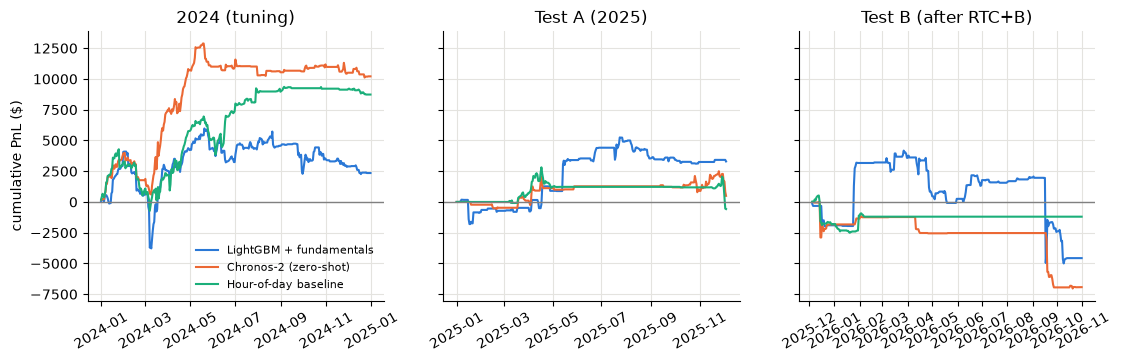

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, p, title in zip(axes, PERIODS, ["2024 (tuning)", "Test A (2025)", "Test B (after RTC+B)"]):
    for m in M:
        d = pd.read_csv(OUTPUT / "backtest" / f"daily_{m}_{p}.csv", parse_dates=["delivery_date"])
        ax.plot(d.delivery_date, d.pnl.cumsum(), color=COLORS[m], label=LABELS[m])
    ax.axhline(0, color="gray", lw=1); ax.set_title(title); ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("cumulative PnL ($)"); axes[0].legend(fontsize=8)
fig.savefig(FIG / "equity_curves.png", bbox_inches="tight", dpi=150); plt.show()

**Takeaways from the equity curves.**
- **Profit comes in jumps, not a steady climb.** Most of each year's result is made or lost in a few short episodes;
  flat stretches are days where the entry rule didn't fire.
- **2024:** Chronos-2 and the baseline make nearly all their profit between March and July, then go flat.
- **Test A:** LightGBM's lead comes mostly from one jump around May.
- **Test B:** LightGBM was up about 4,000 USD in March, slid back towards zero, then crashed in September. One hour
  on 17 Sep 2026 lost 3,700 USD, which shows how a few extreme hours decide the result.
- **Costs:** LightGBM's breakeven fee is about 0.31 USD/MWh, below the 0.50 USD we assume.

## 5. Conclusions

- **Forecasting works.** LightGBM with wind, solar and load forecasts predicts the auction's error better than a
  large pretrained model (Chronos-2) and a simple baseline, in every period and without look-ahead.
- **Trading doesn't, yet.** After fees, the edge is too small and too noisy to tell from luck. The day-ahead
  auction already prices the public information well. What remains is mostly real-time surprises (plant
  failures, sudden wind drops) that can't be known the day before.
- **We compete with the auction using the same public data.** The day-ahead price is itself a forecast, made by
  many professional traders who see the same ERCOT wind, solar and load forecasts and the same price history we use.
  To beat it with the same inputs, we'd need a much smarter model that extracts insights the whole market misses.
  The realistic alternative is **better data**: more accurate weather and wind forecasts, proprietary congestion and
  transmission-outage models, faster information. That data comes from paid commercial providers, which we don't
  have access to. With public data only, a small, noisy edge is what we should expect, and it's what we found.
- **A few hours decide the result, so luck is hard to rule out.** The error has fat tails: about 0.6% of hours
  (errors above 50 USD) make up 11% of all the error, and a single hour can outweigh months of small gains (17 Sep 2026
  alone lost 3,700 USD of LightGBM's −4,566 USD in Test B). Profit therefore depends on being on the right side of a
  handful of extreme hours, and our models predict *when* the market is volatile much better than *which way* it
  breaks. With so few decisive events per year, the confidence intervals stay wide and we can't separate skill
  from luck.
- **The market change matters.** Every model lost money after RTC+B, where the error became more volatile. One
  tuning year from before the change isn't enough.
- **In-sample results mislead.** The best model on 2024 (Chronos-2) was the worst out of sample, which is why we
  tune on one period and judge on others.

**Limitations.**
- The 0.50 USD/MWh fee is assumed; real broker fees are private.
- Collateral and our own price impact are not modelled.
- The weather rule is a price-spike proxy, not real weather alerts.
- The API history starts in December 2023, so there is only one tuning year.

**Next steps.**
- Retrain and re-tune on post-RTC+B data.
- Add planned transmission line outages, which are public before the bid and directly affect West→North.
- Predict *when* big errors happen (classify |error| > 50 USD) rather than the median.
- Add a second pair (West→South) under the shared 40 MW/day budget.

**Reproduce:** run `uv run python src/lgbm.py test_a` (also `test_b`, and with no argument for 2024), then
`uv run python src/backtest.py`, then rerun this notebook. `uv run pytest` runs the look-ahead tests.